# Example: MUSICA CO Single-Tracer Transport

Dry-deposition-style example driver.

This notebook imports reusable routines from:

```python
tagged_tracer_core.py
```

Current simplified goal:

1. Normal `CO` emissions occur in every grid cell.
2. `CO_tracer` emissions occur only in one tagged source grid cell.
3. MUSICA handles local emissions/losses.
4. A simple explicit transport operator moves `CO` and `CO_tracer`.
5. A receptor grid cell is diagnosed to confirm source-to-receptor transport.

This stays independent of plume rise, fire emissions, biogenic emissions, and full WRF/MPAS transport for now, but the functions are organized so those tendencies can be plugged in later.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import musica
import musica.mechanism_configuration as mc

from quacs.tagged_tracers.voc_nox.tagged_tracer_core import (
    build_1d_grid,
    derive_simple_met,
    build_total_co_emissions,
    build_single_cell_tracer_emissions,
    build_musica_rate_parameters,
    transport_1d_advection_diffusion,
    source_receptor_proof_table,
    history_to_dataframe,
)

np.set_printoptions(suppress=True)
pd.set_option("display.float_format", str)


## 1. Define grid and tagged source/receptor cells

In [2]:
num_grid_cells = 30

source_cell = 6
receptor_cell = 20

grid = build_1d_grid(
    num_grid_cells=num_grid_cells,
    source_cell=source_cell,
    receptor_cell=receptor_cell,
)

print(f"Number of MUSICA grid cells: {num_grid_cells}")
print(f"Tagged source cell: {source_cell}")
print(f"Receptor cell: {receptor_cell}")


Number of MUSICA grid cells: 30
Tagged source cell: 6
Receptor cell: 20


## 2. Define meteorological inputs

In [3]:
met = derive_simple_met(
    num_grid_cells=num_grid_cells,
    temperature=298.0,
    pressure=101325.0,
)

temperature = met["temperature"]
pressure = met["pressure"]

print("temperature shape:", temperature.shape)
print("pressure shape:", pressure.shape)


temperature shape: (30,)
pressure shape: (30,)


## 3. Build MUSICA mechanism

In [4]:
CO = mc.Species(name="CO")
CO_tracer = mc.Species(name="CO_tracer")

species = [CO, CO_tracer]
gas = mc.Phase(name="gas", species=species)

r_co_emis = mc.Emission(
    name="CO_emission",
    scaling_factor=1.0,
    products=[CO],
    gas_phase=gas,
)

r_co_tracer_emis = mc.Emission(
    name="CO_tracer_emission",
    scaling_factor=1.0,
    products=[CO_tracer],
    gas_phase=gas,
)

r_co_loss = mc.FirstOrderLoss(
    name="CO_loss",
    scaling_factor=1.0,
    reactants=[CO],
    gas_phase=gas,
)

r_co_tracer_loss = mc.FirstOrderLoss(
    name="CO_tracer_loss",
    scaling_factor=1.0,
    reactants=[CO_tracer],
    gas_phase=gas,
)

mechanism = mc.Mechanism(
    name="single_co_tracer_transport",
    species=species,
    phases=[gas],
    reactions=[
        r_co_emis,
        r_co_tracer_emis,
        r_co_loss,
        r_co_tracer_loss,
    ],
)

for reaction in mechanism.reactions:
    print(f"[{reaction.type.name}] {reaction.to_equation()}")


[Emission] -> CO
[Emission] -> CO_tracer
[FirstOrderLoss] CO ->
[FirstOrderLoss] CO_tracer ->


## 4. Create solver and state

In [5]:
solver = musica.MICM(
    mechanism=mechanism,
    solver_type=musica.SolverType.rosenbrock_standard_order,
)

state = solver.create_state(num_grid_cells)

state.set_conditions(
    temperatures=temperature,
    pressures=pressure,
)

state.set_concentrations({
    "CO": np.zeros(num_grid_cells),
    "CO_tracer": np.zeros(num_grid_cells),
})


## 5. Build emissions and MUSICA rate parameters

In [6]:
CO_emis = build_total_co_emissions(
    grid=grid,
    base_emis=1.0e-12,
    enhancement=5.0e-13,
    enhancement_center=12.0,
    enhancement_width=30.0,
)

CO_tracer_emis = build_single_cell_tracer_emissions(
    total_co_emis=CO_emis,
    source_cell=source_cell,
)

rate_parameters = build_musica_rate_parameters(
    co_emis=CO_emis,
    co_tracer_emis=CO_tracer_emis,
)

state.set_user_defined_rate_parameters(rate_parameters)

print("CO emission at receptor:", CO_emis[receptor_cell])
print("CO_tracer emission at source:", CO_tracer_emis[source_cell])
print("CO_tracer emission at receptor:", CO_tracer_emis[receptor_cell])

assert CO_tracer_emis[source_cell] > 0.0
assert CO_tracer_emis[receptor_cell] == 0.0


CO emission at receptor: 1.0592209145069019e-12
CO_tracer emission at source: 1.150597105956101e-12
CO_tracer emission at receptor: 0.0


## 6. Run MUSICA + explicit transport

In [7]:
dt = 10.0
sim_length = 3000.0
dx = 1.0

K_diff = 0.002
u_adv = 0.006

times = np.arange(0, sim_length + dt, dt)

CO_hist = []
CO_tracer_hist = []

for time_s in times:
    conc_now = state.get_concentrations()
    CO_hist.append(conc_now["CO"].copy())
    CO_tracer_hist.append(conc_now["CO_tracer"].copy())

    # Local MUSICA box-model step
    solver.solve(state, dt)

    conc_after_musica = state.get_concentrations()

    # Explicit transport step
    CO_transported = transport_1d_advection_diffusion(
        C=conc_after_musica["CO"],
        K_diff=K_diff,
        u_adv=u_adv,
        dx=dx,
        dt=dt,
    )

    CO_tracer_transported = transport_1d_advection_diffusion(
        C=conc_after_musica["CO_tracer"],
        K_diff=K_diff,
        u_adv=u_adv,
        dx=dx,
        dt=dt,
    )

    state.set_concentrations({
        "CO": CO_transported,
        "CO_tracer": CO_tracer_transported,
    })

CO_hist = np.asarray(CO_hist)
CO_tracer_hist = np.asarray(CO_tracer_hist)

print("CO_hist shape:", CO_hist.shape)
print("CO_tracer_hist shape:", CO_tracer_hist.shape)


CO_hist shape: (301, 30)
CO_tracer_hist shape: (301, 30)


## 7. Source-receptor proof

In [8]:
proof = source_receptor_proof_table(
    times=times,
    co_hist=CO_hist,
    co_tracer_hist=CO_tracer_hist,
    co_tracer_emis=CO_tracer_emis,
    source_cell=source_cell,
    receptor_cell=receptor_cell,
)

display(proof.head())
display(proof.tail())

print("Max tracer emission at receptor:", CO_tracer_emis[receptor_cell])
print("Max tracer concentration at receptor:", proof["CO_tracer_at_receptor"].max())

assert CO_tracer_emis[receptor_cell] == 0.0
assert proof["CO_tracer_at_receptor"].max() > 0.0

print("PASSED: receptor CO_tracer becomes nonzero even though receptor CO_tracer emission is zero.")


,time.s,CO_at_receptor,CO_tracer_at_source,CO_tracer_at_receptor,CO_tracer_emis_at_source,CO_tracer_emis_at_receptor
0,0.0,0.0,0.0,0.0,1.150597105956101e-12,0.0
1,10.0,1.0617819806970361e-11,1.0355373953604908e-11,0.0,1.150597105956101e-12,0.0
2,20.0,2.126181068404322e-11,1.9712029619239918e-11,0.0,1.150597105956101e-12,0.0
3,30.0,3.193252485954504e-11,2.81992941116145e-11,0.0,1.150597105956101e-12,0.0
4,40.0,4.263050575508703e-11,3.592747931742625e-11,0.0,1.150597105956101e-12,0.0


,time.s,CO_at_receptor,CO_tracer_at_source,CO_tracer_at_receptor,CO_tracer_emis_at_source,CO_tracer_emis_at_receptor
296,2960.0,3.6893263222855388e-09,1.8033942124609868e-10,1.3572319968974927e-10,1.150597105956101e-12,0.0
297,2970.0,3.7003192557071815e-09,1.8034354761947115e-10,1.3640509284197076e-10,1.150597105956101e-12,0.0
298,2980.0,3.711300378499371e-09,1.8034762837045002e-10,1.3708105596089643e-10,1.150597105956101e-12,0.0
299,2990.0,3.722269807746904e-09,1.8035166453799947e-10,1.3775108814743597e-10,1.150597105956101e-12,0.0
300,3000.0,3.733227660082678e-09,1.8035565713720008e-10,1.3841518993982318e-10,1.150597105956101e-12,0.0


Max tracer emission at receptor: 0.0
Max tracer concentration at receptor: 1.3841518993982318e-10
PASSED: receptor CO_tracer becomes nonzero even though receptor CO_tracer emission is zero.


## 8. Spatial tracer evolution

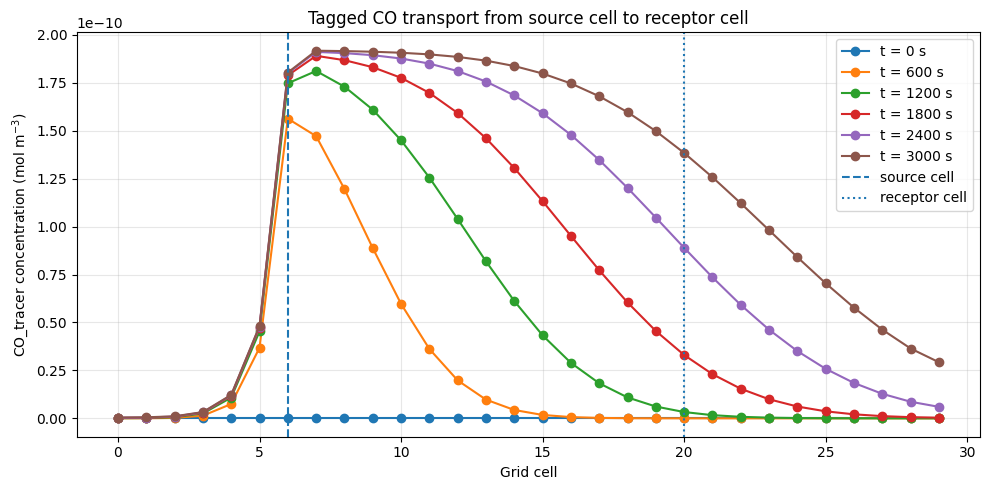

In [9]:
plt.figure(figsize=(10, 5))

time_indices = [
    0,
    int(0.20 * (len(times) - 1)),
    int(0.40 * (len(times) - 1)),
    int(0.60 * (len(times) - 1)),
    int(0.80 * (len(times) - 1)),
    len(times) - 1,
]

for ti in time_indices:
    plt.plot(
        grid,
        CO_tracer_hist[ti, :],
        marker="o",
        label=f"t = {times[ti]:.0f} s",
    )

plt.axvline(source_cell, linestyle="--", label="source cell")
plt.axvline(receptor_cell, linestyle=":", label="receptor cell")

plt.xlabel("Grid cell")
plt.ylabel("CO_tracer concentration (mol m$^{-3}$)")
plt.title("Tagged CO transport from source cell to receptor cell")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 9. Receptor time series

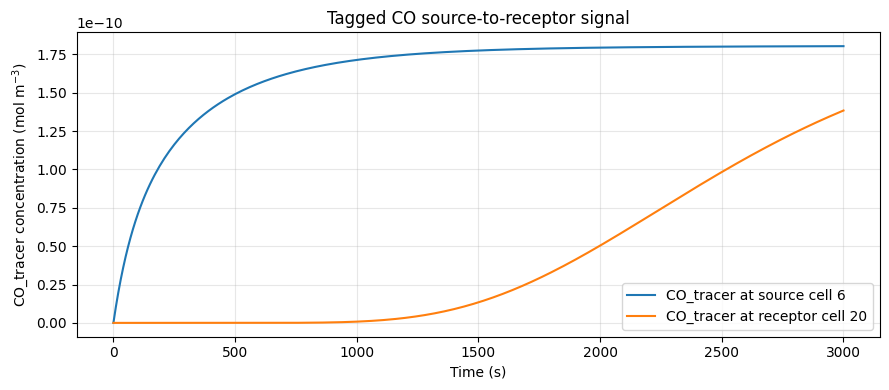

In [10]:
plt.figure(figsize=(9, 4))

plt.plot(
    times,
    CO_tracer_hist[:, source_cell],
    label=f"CO_tracer at source cell {source_cell}",
)

plt.plot(
    times,
    CO_tracer_hist[:, receptor_cell],
    label=f"CO_tracer at receptor cell {receptor_cell}",
)

plt.xlabel("Time (s)")
plt.ylabel("CO_tracer concentration (mol m$^{-3}$)")
plt.title("Tagged CO source-to-receptor signal")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 10. Heatmap

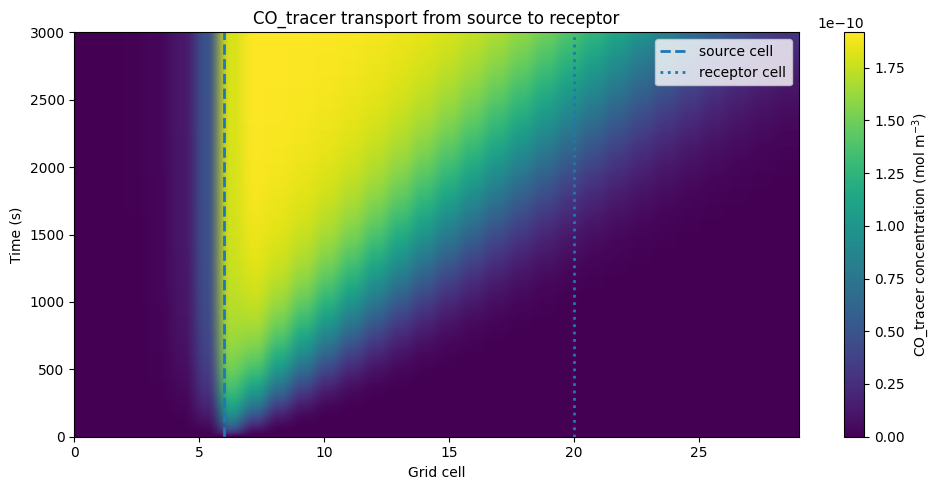

In [11]:
plt.figure(figsize=(10, 5))

plt.imshow(
    CO_tracer_hist,
    aspect="auto",
    origin="lower",
    extent=[grid.min(), grid.max(), times.min(), times.max()],
)

plt.axvline(source_cell, linestyle="--", linewidth=2, label="source cell")
plt.axvline(receptor_cell, linestyle=":", linewidth=2, label="receptor cell")

plt.colorbar(label="CO_tracer concentration (mol m$^{-3}$)")
plt.xlabel("Grid cell")
plt.ylabel("Time (s)")
plt.title("CO_tracer transport from source to receptor")
plt.legend()
plt.tight_layout()
plt.show()


## 11. Total CO vs tagged source contribution at receptor

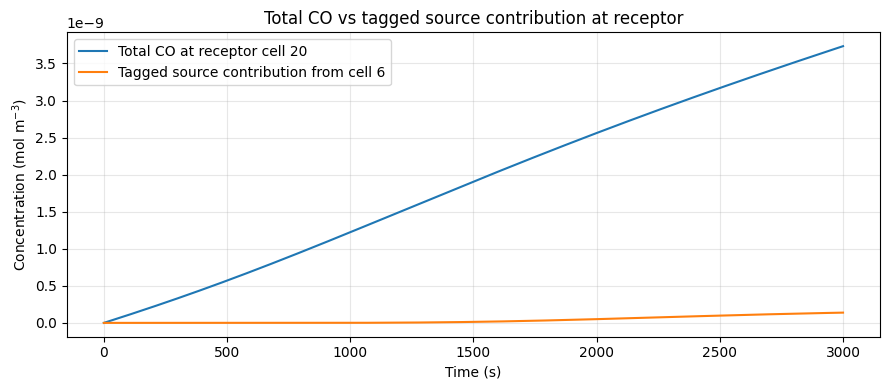

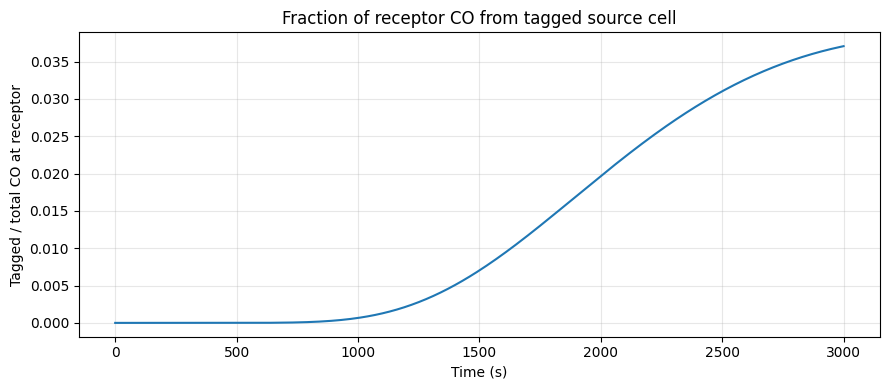

In [12]:
plt.figure(figsize=(9, 4))

plt.plot(
    times,
    CO_hist[:, receptor_cell],
    label=f"Total CO at receptor cell {receptor_cell}",
)

plt.plot(
    times,
    CO_tracer_hist[:, receptor_cell],
    label=f"Tagged source contribution from cell {source_cell}",
)

plt.xlabel("Time (s)")
plt.ylabel("Concentration (mol m$^{-3}$)")
plt.title("Total CO vs tagged source contribution at receptor")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

ratio = np.divide(
    CO_tracer_hist[:, receptor_cell],
    CO_hist[:, receptor_cell],
    out=np.zeros_like(times, dtype=float),
    where=CO_hist[:, receptor_cell] > 0,
)

plt.figure(figsize=(9, 4))
plt.plot(times, ratio)
plt.xlabel("Time (s)")
plt.ylabel("Tagged / total CO at receptor")
plt.title("Fraction of receptor CO from tagged source cell")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 12. Save outputs

In [ ]:
df = history_to_dataframe(
    times=times,
    grid=grid,
    co_hist=CO_hist,
    co_tracer_hist=CO_tracer_hist,
    co_emis=CO_emis,
    co_tracer_emis=CO_tracer_emis,
    temperature=temperature,
    pressure=pressure,
    source_cell=source_cell,
    receptor_cell=receptor_cell,
)

df.to_csv("ex_tagged_co_musica_transport_output.csv", index=False)
proof.to_csv("ex_tagged_co_musica_transport_proof.csv", index=False)
mechanism.export("ex_tagged_co_musica_transport_mechanism.json")

display(df.head())

print("Wrote:")
print("ex_tagged_co_musica_transport_output.csv")
print("ex_tagged_co_musica_transport_proof.csv")
print("ex_tagged_co_musica_transport_mechanism.json")
